In [124]:
import pandas as pd
from odds import *
import matplotlib.pyplot as plt

### The bookmaker's margin, and are they right? 

In [125]:
pl = pd.read_csv('data/pl_matches.csv', low_memory=False)
pl = pl.sort_values("Date").reset_index(drop=True)
data = pl[['Season', 'Date', 'FTR', 'B365H', 'B365D', 'B365A']]

In [126]:
data.head()

,Season,Date,FTR,B365H,B365D,B365A
0,2010-11,2010-08-14,H,2.00,3.30,4.0
1,2010-11,2010-08-14,H,2.88,3.25,2.5
2,2010-11,2010-08-14,D,2.20,3.30,3.4
3,2010-11,2010-08-14,H,1.17,7.00,17.0
4,2010-11,2010-08-14,D,2.10,3.30,3.6


In [127]:
imp = decimal_to_prob(data[['B365H','B365D','B365A']])
imp['overround'] = (imp[['B365H', 'B365D', 'B365A']].sum(axis=1) - 1)
imp['Season'] = data['Season']
imp['FTR'] = data['FTR']

In [128]:
imp.head()

,B365H,B365D,B365A,overround,Season,FTR
0,0.500000,0.303030,0.250000,0.053030,2010-11,H
1,0.347222,0.307692,0.400000,0.054915,2010-11,H
2,0.454545,0.303030,0.294118,0.051693,2010-11,D
3,0.854701,0.142857,0.058824,0.056382,2010-11,H
4,0.476190,0.303030,0.277778,0.056999,2010-11,D


In [129]:
avg_overround = imp.groupby('Season').overround.mean()
avg_overround

Season
2010-11    0.054494
2011-12    0.054627
2012-13    0.041113
2013-14    0.026150
2014-15    0.026682
2015-16    0.027653
2016-17    0.029498
2017-18    0.031053
2018-19    0.027788
2019-20    0.053090
2020-21    0.054475
2021-22    0.054100
2022-23    0.053707
2023-24    0.053972
2024-25    0.055327
Name: overround, dtype: float64

Text(0.5, 1.0, 'Average overround per season')

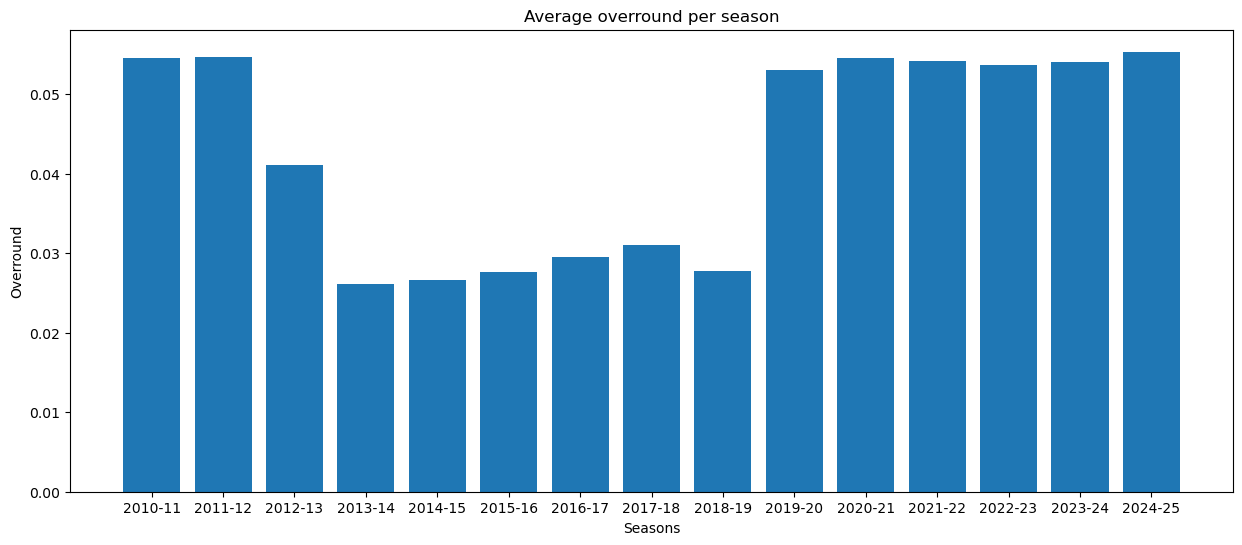

In [130]:
plt.figure(figsize=(15,6))
plt.bar(avg_overround.index,avg_overround.values)
plt.ylabel('Overround')
plt.xlabel('Seasons')
plt.title('Average overround per season')

It varies between about 2.6% and 5.5%.

Normalising to fair probabilities

In [131]:
nimp = imp[['B365H', 'B365D', 'B365A']]
total = nimp.sum(axis = 1)

nimp = nimp.div(total,axis=0)
nimp.head()

,B365H,B365D,B365A
0,0.474820,0.287770,0.237410
1,0.329147,0.291675,0.379178
2,0.432203,0.288136,0.279661
3,0.809083,0.135233,0.055684
4,0.450512,0.286689,0.262799


In [132]:
nimp.sum(axis=1).head()

0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
dtype: float64

Are the fair probabilities honest? 

In [135]:
bins = [0, .2, .3, .4, .5, .6, .7, .8, 1]
homebins = pd.cut(nimp.B365H, bins = bins)

imp['homebins'] = homebins
imp['p_home'] = nimp['B365H']
imp['home_win'] = imp['FTR'] == 'H'
imp.head()

,B365H,B365D,B365A,overround,Season,FTR,p_home,home_win,homebins
0,0.500000,0.303030,0.250000,0.053030,2010-11,H,0.474820,True,"(0.4, 0.5]"
1,0.347222,0.307692,0.400000,0.054915,2010-11,H,0.329147,True,"(0.3, 0.4]"
2,0.454545,0.303030,0.294118,0.051693,2010-11,D,0.432203,False,"(0.4, 0.5]"
3,0.854701,0.142857,0.058824,0.056382,2010-11,H,0.809083,True,"(0.8, 1.0]"
4,0.476190,0.303030,0.277778,0.056999,2010-11,D,0.450512,False,"(0.4, 0.5]"


In [141]:
calib = imp.groupby('homebins').agg(
    predicted = ('p_home','mean'),
    actual = ('home_win','mean')
)
calib.head()

C:\Users\PREDATOR\AppData\Local\Temp\ipykernel_118080\1903277524.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  calib = imp.groupby('homebins').agg(


,predicted,actual
homebins,,
"(0.0, 0.2]",0.144642,0.145228
"(0.2, 0.3]",0.251705,0.275714
"(0.3, 0.4]",0.357123,0.341675
"(0.4, 0.5]",0.450532,0.441960
"(0.5, 0.6]",0.547863,0.574468


Text(0.5, 1.0, 'Bet365 is well calibrated')

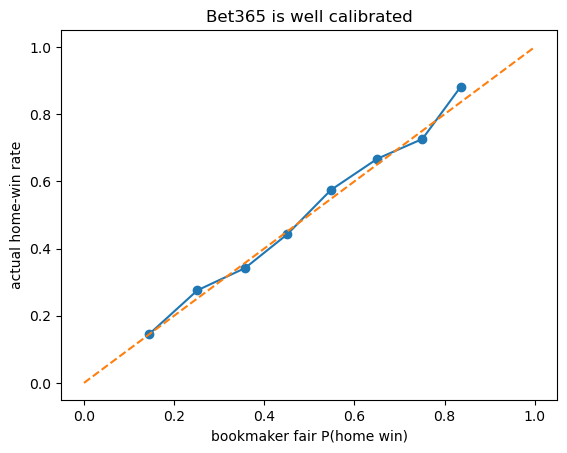

In [145]:
plt.plot(calib.predicted, calib.actual, "o-")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("bookmaker fair P(home win)"); plt.ylabel("actual home-win rate")
plt.title("Bet365 is well calibrated")

Counting the league